In [1]:
### standard libraries
import numpy as np
import matplotlib.pyplot as plt

### other libraries
import finufft

### my modules
from fast_volume_align_ot import utils, plots

In [2]:
# """

# -----------
# CONVENTIONS
# -----------

# Here we will use the physics conventions for spherical coords

# x = [x1, x2, x3] = [x, y, z]

#      r = radius in [-1, 1]
#  theta = polar angle in [0, pi], (the inclination angle), angle wrt positive polar axis
#    phi = azimuthal angle in [0, 2pi), (the inplane angle) angle of rotation around the polar axis

# x1 = r sin(theta) cos(phi)
# x2 = r sin(theta) sin(phi)
# x3 = r cos(phi)


### TODO
# - define the connection between numpy conventions and our conventions
# - e.g., a projection to xy-plane is axis=? in numpy?
# - since numpy uses left-hand grid starting from (0, 0)
# - make index function that identifies angles associated with slice
# - ***make index function that takes the slice/projection associated with angles***
# - should probably rename points to xi_1,2,3 because they are spatial frequency



# """

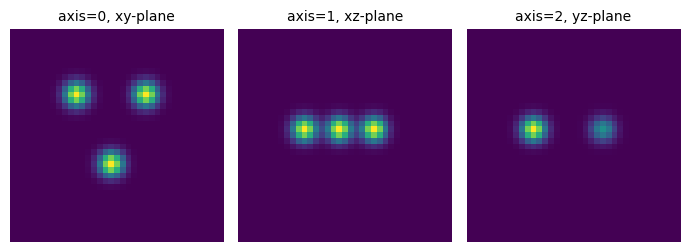

In [3]:
L = 37
sigma = 1.5

vol = utils.generate_3d_triangle_gaussian_shape(L, sigma)
plots.orthogonal_2D_projection_plot(vol)

In [4]:
n_points = L  # number of Fourier grid points per 1D slice, scales with volume size
n_phi = L  # number of projection angles in phi
n_theta = L  # number of projection angles in theta
nz, ny, nx = vol.shape

### start with a central slice along the z-axis
### rotate by theta (around y-axis) to form xz-plane of 1D slices

### EV: TODO: define point spacing based on odd or even grid size (DFT conventions)
### EV: TODO: add option to use Chebyshev or other point spacings
# x3 = np.linspace(-1, 1, n_points, endpoint=False)  # initial Fourier points along z-axis (x3)
x3 = np.linspace(-(1 - (1/n_points)), 1 - (1/n_points), n_points, endpoint=True)  # initial Fourier points along z-axis (x3)
# x3 = np.linspace(1 - (1/n_points), -(1 - (1/n_points)), n_points, endpoint=True)

theta = np.linspace(0, 2*np.pi, n_theta, endpoint=False)

x1_theta = x3[:, np.newaxis] * np.sin(theta)[np.newaxis, :]
x2_theta = np.zeros((n_points, n_theta))
x3_theta = x3[:, np.newaxis] * np.cos(theta)[np.newaxis, :]

### now rotate each slice by phi (around the z-axis)

phi = np.linspace(0, 2*np.pi, n_theta, endpoint=False)

x1_theta_phi = x1_theta[np.newaxis, ...] * np.cos(phi[:, np.newaxis, np.newaxis])
x2_theta_phi = x1_theta[np.newaxis, ...] * np.sin(phi[:, np.newaxis, np.newaxis])
x3_theta_phi = np.ones((n_phi, n_points, n_theta)) * x3_theta

In [5]:
x1_theta.shape, x1_theta_phi.shape

((37, 37), (37, 37, 37))

In [6]:
###                 phi, p, theta
# plt.plot(x1_theta_phi[:, 0, 9])
# plt.plot(x2_theta_phi[:, 0, 9])

In [7]:
### format for fiNUFFT

x1_theta_phi = np.pi * x1_theta_phi.flatten()
x2_theta_phi = np.pi * x2_theta_phi.flatten()
x3_theta_phi = np.pi * x3_theta_phi.flatten()

In [8]:
nufft_type=2
eps=1e-8
n_transforms=1

plan = finufft.Plan(nufft_type, (nx, ny, nz), n_transforms, eps)

### EV: not sure what correct ordering is to match conventions
plan.setpts(x1_theta_phi, x2_theta_phi, x3_theta_phi)

vol_ft_slices = plan.execute(vol.astype(np.complex128))

vol_ft_slices = vol_ft_slices.reshape((n_phi, n_points, n_theta))

vol_projections = np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(vol_ft_slices, axes=1), axis=1), axes=1).real

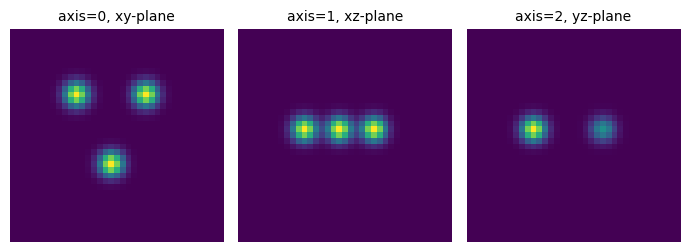

In [9]:
plots.orthogonal_2D_projection_plot(vol.real)

In [10]:
print('thetas :', np.rad2deg(theta))

thetas : [  0.           9.72972973  19.45945946  29.18918919  38.91891892
  48.64864865  58.37837838  68.10810811  77.83783784  87.56756757
  97.2972973  107.02702703 116.75675676 126.48648649 136.21621622
 145.94594595 155.67567568 165.40540541 175.13513514 184.86486486
 194.59459459 204.32432432 214.05405405 223.78378378 233.51351351
 243.24324324 252.97297297 262.7027027  272.43243243 282.16216216
 291.89189189 301.62162162 311.35135135 321.08108108 330.81081081
 340.54054054 350.27027027]


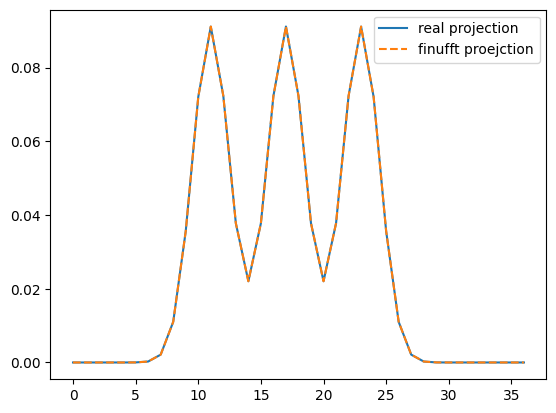

In [11]:
### visualize the three different orthogonal slices
### slice 1
phi_idx = 0
theta_idx = 0
ax1 = 0
ax2 = 1

# ### slice 2
# phi_idx = 9
# theta_idx = 9
# ax1 = 0
# ax2 = 2

# ### slice 3
# phi_idx = 0
# theta_idx = 9
# ax1 = 1
# ax2 = 2

plt.plot(np.sum(vol, axis=(ax1, ax2)), label='real projection')
plt.plot(vol_projections[phi_idx, :, theta_idx], '--', label='finufft proejction')
plt.legend()
plt.show()